# Projet final : les récoltes agricoles

**Équipe :** (nom de l'équipe et des 5 membres)

Une direction départementale de l'agriculture (fictive) vous confie trois ans de récoltes, de 2023 à 2025, par saison (printemps, automne), département et culture, avec la pluie tombée pendant chaque saison. Le ministère veut savoir quelles cultures pèsent le plus, où les rendements sont les meilleurs, et si la pluie explique les mauvaises années.

Ce notebook montre **votre démarche** : chaque étape dit ce que vous cherchez, le code, le résultat et ce que vous en concluez. Les graphiques doivent être visibles : avant de pousser, **Restart**, puis **Run All**.

Le tableau de bord (`app.py`) reprend ensuite vos résultats pour le décideur.

In [1]:
import matplotlib.pyplot as plt
import pandas as pd

brut = pd.read_csv("donnees/recoltes_brut.csv")

## 1. Diagnostic

Forme, types, valeurs manquantes, lignes en double, et toutes les écritures d'une même valeur dans les colonnes de texte. Notez chaque problème trouvé : vous le corrigerez à l'étape 2.

In [2]:
print("Forme :", brut.shape)
print()
print("Types :")
print(brut.dtypes)
print()
print("Valeurs manquantes :")
print(brut.isna().sum())
print()
print("Lignes en double :", brut.duplicated().sum())

Forme : (408, 6)

Types :
annee           int64
saison            str
departement       str
culture           str
surface_ha        str
production_t      str
dtype: object

Valeurs manquantes :
annee            0
saison           0
departement      0
culture          0
surface_ha       0
production_t    15
dtype: int64

Lignes en double : 18


In [3]:
for colonne in ["saison", "departement", "culture"]:
    valeurs = sorted(brut[colonne].unique())
    print(f"{colonne} : {len(valeurs)} écritures différentes")
    print(valeurs)
    print()

saison : 2 écritures différentes
['Automne', 'Printemps']

departement : 44 écritures différentes
[' Artibonite', ' Centre', " Grand'Anse", ' Nord', ' Nord-Est', ' Nord-Ouest', ' Ouest', ' Sud', ' Sud-Est', 'ARTIBONITE', 'Artibonite', 'Centre', "GRAND'ANSE", "Grand'Anse", "Grand'Anse ", 'NIPPES', 'NORD', 'NORD-EST', 'NORD-OUEST', 'Nippes', 'Nippes ', 'Nord', 'Nord ', 'Nord-Est', 'Nord-Est ', 'Nord-Ouest', 'Nord-Ouest ', 'OUEST', 'Ouest', 'Ouest ', 'SUD', 'Sud', 'Sud ', 'Sud-Est', 'Sud-Est ', 'artibonite', 'centre', "grand'anse", 'nord', 'nord-est', 'nord-ouest', 'ouest', 'sud', 'sud-est']

culture : 33 écritures différentes
[' Banane', ' Haricot', ' Igname', ' Maïs', ' Pois congo', ' Riz', ' Sorgho', 'BANANE', 'Banane', 'Banane ', 'HARICOT', 'Haricot', 'Haricot ', 'IGNAME', 'Igname', 'Igname ', 'MAÏS', 'Maïs', 'Maïs ', 'POIS CONGO', 'Pois congo', 'Pois congo ', 'Riz', 'Riz ', 'SORGHO', 'Sorgho', 'Sorgho ', 'banane', 'haricot', 'igname', 'maïs', 'pois congo', 'sorgho']



In [4]:
for colonne in ["surface_ha", "production_t"]:
    converti = pd.to_numeric(brut[colonne], errors="coerce")
    non_convertibles = brut.loc[converti.isna() & brut[colonne].notna(), colonne]
    print(f"{colonne} : {len(non_convertibles)} valeurs qui ne se convertissent pas en nombre")
    print(non_convertibles.head(8).tolist())
    print()

surface_ha : 22 valeurs qui ne se convertissent pas en nombre
['2 517', '541 ha', '1 127', '1 185', '1 185', '1 748', '492 ha', '997 ha']

production_t : 50 valeurs qui ne se convertissent pas en nombre
['3753 t', '2299 t', '1306 t', '2394 t', '599 t', '767 t', '8147 t', '2089 t']



**Les problèmes trouvés :**

- `surface_ha` et `production_t` sont lues comme du **texte** : certaines valeurs portent une unité (`541 ha`, `3753 t`) ou un espace comme séparateur de milliers (`2 517`).
- `production_t` a **15 valeurs manquantes**.
- Le fichier contient **18 lignes en double**.
- `departement` s'écrit de **44 façons** pour 10 départements, et `culture` de **33 façons** pour 7 cultures : majuscules, minuscules et espaces autour du nom.
- `saison` est propre : seulement `Printemps` et `Automne`.

## 2. Nettoyage

Une copie `propre`, puis une cellule par problème, en comptant les lignes avant et après chaque suppression. Dites ce que vous supprimez et pourquoi.

**Contrôle :** à la fin, `propre.shape` vaut `(376, 6)`, sans valeur manquante ni doublon, avec 2 valeurs dans `saison`, 10 valeurs dans `departement`, 7 valeurs dans `culture`.

In [5]:
propre = brut.copy()
print("Lignes au départ :", len(propre))

# On enlève l'unité (ha, t) et les espaces, puis on convertit en nombre
for colonne in ["surface_ha", "production_t"]:
    propre[colonne] = pd.to_numeric(propre[colonne].str.replace(r"ha|t|\s", "", regex=True), errors="coerce")

print()
print(propre[["surface_ha", "production_t"]].dtypes)
print()
print("Valeurs manquantes :")
print(propre[["surface_ha", "production_t"]].isna().sum())

Lignes au départ : 408

surface_ha        int64
production_t    float64
dtype: object

Valeurs manquantes :
surface_ha       0
production_t    15
dtype: int64


In [6]:
# Les noms officiels viennent des fichiers departements.csv et cultures.csv
departements = pd.read_csv("donnees/departements.csv")
cultures = pd.read_csv("donnees/cultures.csv")

noms_departements = {nom.lower(): nom for nom in departements["departement"]}
noms_cultures = {nom.lower(): nom for nom in cultures["culture"]}

propre["departement"] = propre["departement"].str.strip().str.lower().map(noms_departements)
propre["culture"] = propre["culture"].str.strip().str.lower().map(noms_cultures)

print("Départements :", propre["departement"].nunique(), "| noms non reconnus :", propre["departement"].isna().sum())
print("Cultures :", propre["culture"].nunique(), "| noms non reconnus :", propre["culture"].isna().sum())

Départements : 10 | noms non reconnus : 0
Cultures : 7 | noms non reconnus : 0


In [7]:
avant = len(propre)
propre = propre.drop_duplicates()
print("Lignes avant :", avant)
print("Lignes après :", len(propre))
print("Doublons supprimés :", avant - len(propre))

Lignes avant : 408
Lignes après : 390
Doublons supprimés : 18


In [8]:
avant = len(propre)
propre = propre.dropna(subset=["production_t"])
print("Lignes avant :", avant)
print("Lignes après :", len(propre))
print("Lignes sans production supprimées :", avant - len(propre))

Lignes avant : 390
Lignes après : 376
Lignes sans production supprimées : 14


In [9]:
# Sans valeur manquante, les nombres peuvent redevenir des entiers
propre["surface_ha"] = propre["surface_ha"].astype(int)
propre["production_t"] = propre["production_t"].astype(int)
propre = propre.reset_index(drop=True)

print("Forme :", propre.shape)
print("Valeurs manquantes :", propre.isna().sum().sum())
print("Doublons :", propre.duplicated().sum())
print("Saisons :", propre["saison"].nunique(), "| départements :", propre["departement"].nunique(), "| cultures :", propre["culture"].nunique())

controle = (
    propre.shape == (376, 6)
    and propre.isna().sum().sum() == 0
    and propre.duplicated().sum() == 0
    and propre["saison"].nunique() == 2
    and propre["departement"].nunique() == 10
    and propre["culture"].nunique() == 7
)
print("Contrôle réussi :", controle)

Forme : (376, 6)
Valeurs manquantes : 0
Doublons : 0
Saisons : 2 | départements : 10 | cultures : 7
Contrôle réussi : True


## 3. Jointures

Joignez `propre` avec `cultures.csv`, `pluies.csv`, et ajoutez les colonnes calculées dont vous aurez besoin. Comptez les lignes avant et après chaque `merge`.

**Contrôle :** 376 lignes après les jointures, autant qu'avant.

In [10]:
pluies = pd.read_csv("donnees/pluies.csv")

print("Lignes avant les jointures :", len(propre))

complet = propre.merge(cultures, on="culture", how="left")
print("Après la jointure avec cultures.csv :", len(complet))

complet = complet.merge(pluies, on=["annee", "saison", "departement"], how="left")
print("Après la jointure avec pluies.csv :", len(complet))

complet = complet.merge(departements, on="departement", how="left")
print("Après la jointure avec departements.csv :", len(complet))

# Colonnes calculées : le rendement (t/ha) et la valeur de la production (gourdes)
complet["rendement_t_ha"] = complet["production_t"] / complet["surface_ha"]
complet["valeur_htg"] = complet["production_t"] * 1000 * complet["prix_htg_kg"]

print()
print("Forme :", complet.shape)
print("Valeurs manquantes :", complet.isna().sum().sum())
print("Contrôle réussi :", len(complet) == 376 and complet.isna().sum().sum() == 0)

Lignes avant les jointures : 376
Après la jointure avec cultures.csv : 376
Après la jointure avec pluies.csv : 376
Après la jointure avec departements.csv : 376

Forme : (376, 15)
Valeurs manquantes : 0
Contrôle réussi : True


Enregistrez le tableau complet : c'est le fichier que lit le tableau de bord.

```python
complet.to_csv("donnees/recoltes_propre.csv", index=False)
```

In [11]:
complet.to_csv("donnees/recoltes_propre.csv", index=False)

recoltes = pd.read_csv("donnees/recoltes_propre.csv")
print("Fichier relu :", recoltes.shape)
print(recoltes.dtypes)

Fichier relu : (376, 15)
annee                     int64
saison                      str
departement                 str
culture                     str
surface_ha                int64
production_t              int64
famille                     str
rendement_moyen_t_ha    float64
prix_htg_kg             float64
pluie_mm                  int64
chef_lieu                   str
population                int64
superficie_km2            int64
rendement_t_ha          float64
valeur_htg              float64
dtype: object


## 4. Quelles cultures pèsent le plus, en tonnes puis en valeur (gourdes) ? Le classement change-t-il ?

            tonnes  rang_tonnes  valeur_millions_htg  rang_valeur
culture                                                          
Banane      547615            1                 6571            2
Igname      402302            2                12069            1
Riz         136225            3                 5177            3
Maïs         75311            4                 1657            6
Sorgho       61354            5                 1227            7
Pois congo   56626            6                 3114            4
Haricot      42323            7                 2751            5


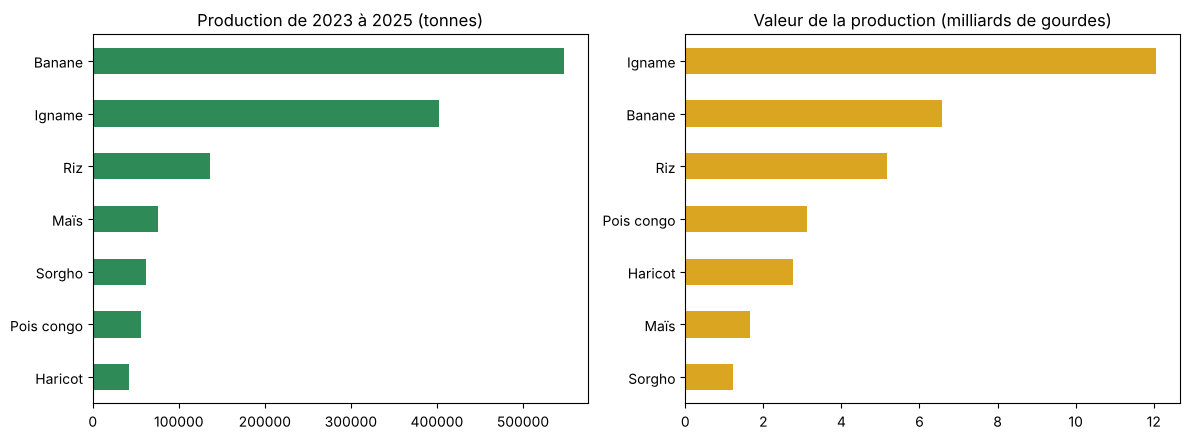

In [12]:
poids = recoltes.groupby("culture").agg(
    tonnes=("production_t", "sum"),
    valeur_htg=("valeur_htg", "sum"),
)
poids["rang_tonnes"] = poids["tonnes"].rank(ascending=False).astype(int)
poids["rang_valeur"] = poids["valeur_htg"].rank(ascending=False).astype(int)
poids["valeur_millions_htg"] = (poids["valeur_htg"] / 1e6).round().astype(int)

print(poids.sort_values("tonnes", ascending=False)[["tonnes", "rang_tonnes", "valeur_millions_htg", "rang_valeur"]])

fig, axes = plt.subplots(1, 2, figsize=(12, 4.5))
poids["tonnes"].sort_values().plot.barh(ax=axes[0], color="seagreen")
axes[0].set_title("Production de 2023 à 2025 (tonnes)")
(poids["valeur_htg"] / 1e9).sort_values().plot.barh(ax=axes[1], color="goldenrod")
axes[1].set_title("Valeur de la production (milliards de gourdes)")
for ax in axes:
    ax.set_ylabel("")
fig.tight_layout()
plt.show()

**Ce qu'on en conclut :** En tonnes, la banane (547 615 t) et l'igname (402 302 t) dominent, devant le riz (136 225 t). En valeur, l'igname passe en tête (12,07 milliards de gourdes) devant la banane (6,57) : le classement change. Le haricot et le pois congo, derniers en tonnes (42 323 t et 56 626 t), gagnent chacun deux places en valeur (5e et 4e) grâce à leur prix (65 et 55 gourdes le kilo), au détriment du maïs et du sorgho (6e et 7e).

## 5. Où les rendements (tonnes par hectare) sont-ils les meilleurs, culture par culture ?

departement  Artibonite  Centre  Grand'Anse  Nippes  Nord  Nord-Est  \
culture                                                               
Banane             7.10    6.64        8.66    7.21  9.05      6.23   
Haricot            0.64    0.78        0.69    0.71  0.70      0.61   
Igname             5.79    5.53        8.24    5.30  5.74      5.32   
Maïs               0.96    1.20        1.11    1.05  1.08      0.91   
Pois congo         0.77    0.82        0.73    0.76  0.74      0.63   
Riz                3.80     NaN         NaN     NaN  2.43      2.12   
Sorgho             0.79    1.08        0.91    0.85  0.90      0.77   

departement  Nord-Ouest  Ouest   Sud  Sud-Est  
culture                                        
Banane             6.55   6.89  8.01     7.04  
Haricot            0.60   0.63  0.88     0.66  
Igname             5.44   5.74  6.56     5.76  
Maïs               0.99   1.06  1.15     0.92  
Pois congo         1.01   0.80  0.80     0.76  
Riz                 NaN 

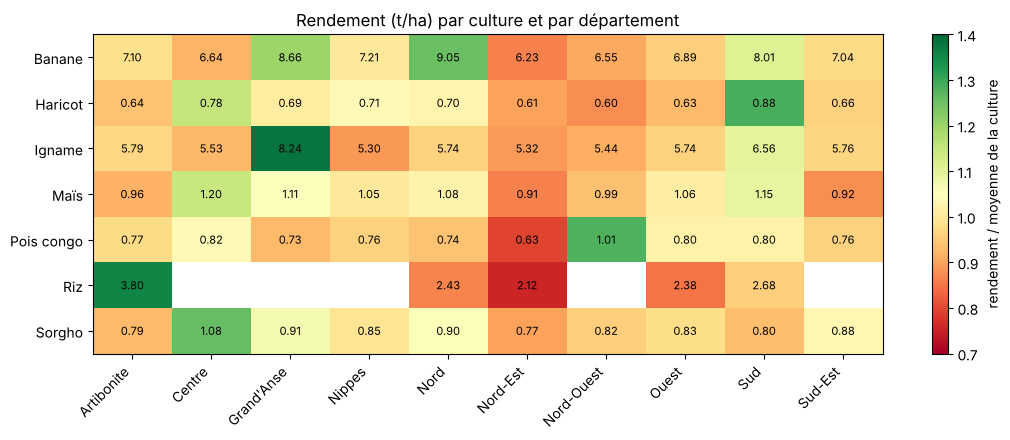

In [13]:
totaux = recoltes.groupby(["culture", "departement"])[["production_t", "surface_ha"]].sum()
rendements = (totaux["production_t"] / totaux["surface_ha"]).unstack()
national = recoltes.groupby("culture")["production_t"].sum() / recoltes.groupby("culture")["surface_ha"].sum()

meilleurs = pd.DataFrame({
    "meilleur département": rendements.idxmax(axis=1),
    "rendement (t/ha)": rendements.max(axis=1).round(2),
    "moyenne nationale (t/ha)": national.round(2),
    "plus faible département": rendements.idxmin(axis=1),
    "rendement le plus faible (t/ha)": rendements.min(axis=1).round(2),
})
print(rendements.round(2))
print()
print(meilleurs)

# Carte de chaleur : la couleur compare chaque rendement à la moyenne de sa culture
relatif = rendements.div(national, axis=0)
fig, ax = plt.subplots(figsize=(11, 4.5))
image = ax.imshow(relatif.values, cmap="RdYlGn", vmin=0.7, vmax=1.4, aspect="auto")
ax.set_xticks(range(len(rendements.columns)))
ax.set_xticklabels(rendements.columns, rotation=45, ha="right")
ax.set_yticks(range(len(rendements.index)))
ax.set_yticklabels(rendements.index)
for i in range(rendements.shape[0]):
    for j in range(rendements.shape[1]):
        valeur = rendements.iloc[i, j]
        if pd.notna(valeur):
            ax.text(j, i, f"{valeur:.2f}", ha="center", va="center", fontsize=8)
fig.colorbar(image, ax=ax, label="rendement / moyenne de la culture")
ax.set_title("Rendement (t/ha) par culture et par département")
fig.tight_layout()
plt.show()

**Ce qu'on en conclut :** aucun département n'est le meilleur partout : le Nord est premier pour la banane (9,05 t/ha), la Grand'Anse pour l'igname (8,24), l'Artibonite pour le riz (3,80), le Centre pour le maïs (1,20) et le sorgho (1,08), le Sud pour le haricot (0,88) et le Nord-Ouest pour le pois congo (1,01). Le Nord-Est a le rendement le plus faible pour cinq cultures sur sept (banane, maïs, pois congo, riz, sorgho). Le riz n'est cultivé que dans cinq départements.

## 6. La pluie explique-t-elle les rendements ? Pour quelles cultures ? Montrez-le avec des nuages de points.

Corrélation entre la pluie et le rendement :
            relevés  toutes saisons  automne  printemps
culture                                                
Haricot          56            0.76     0.67       0.77
Maïs             58            0.76     0.72       0.69
Igname           59            0.69     0.67       0.60
Sorgho           56            0.68     0.56       0.68
Banane           59            0.65     0.59       0.60
Pois congo       58            0.63     0.54       0.60
Riz              30            0.42     0.06       0.43

Pluie moyenne par saison (mm) :
saison
Automne      352.0
Printemps    481.0
Name: pluie_mm, dtype: float64

Rendement moyen par culture et par saison (t/ha) :
saison      Automne  Printemps
culture                       
Banane         6.66       7.78
Haricot        0.64       0.72
Igname         5.56       6.37
Maïs           0.97       1.12
Pois congo     0.75       0.83
Riz            2.51       3.16
Sorgho         0.79       0.91


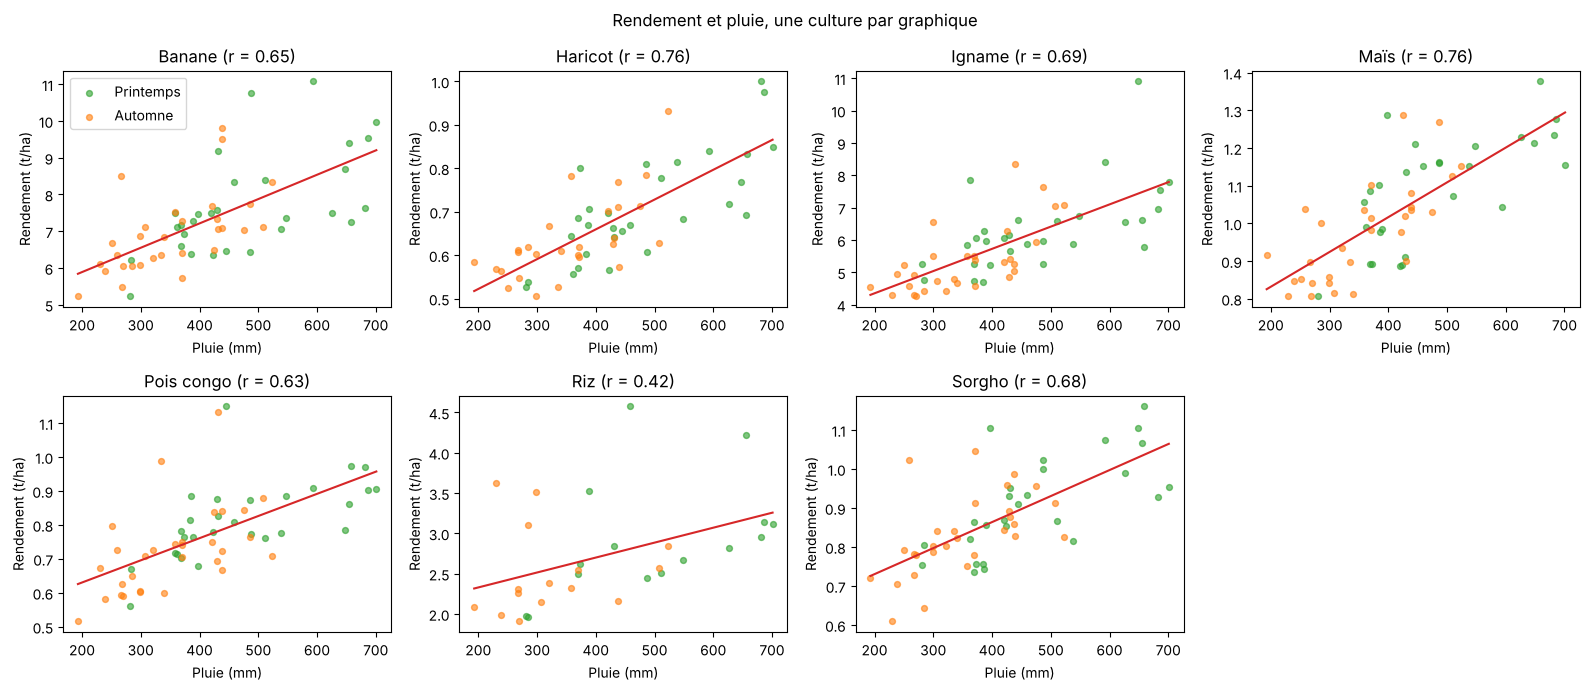

In [14]:
import numpy as np

lignes_corr = []
for culture, g in recoltes.groupby("culture"):
    ligne = {"culture": culture, "relevés": len(g), "toutes saisons": g["rendement_t_ha"].corr(g["pluie_mm"])}
    for saison, s in g.groupby("saison"):
        ligne[saison.lower()] = s["rendement_t_ha"].corr(s["pluie_mm"])
    lignes_corr.append(ligne)
correlations = pd.DataFrame(lignes_corr).set_index("culture").round(2)
print("Corrélation entre la pluie et le rendement :")
print(correlations.sort_values("toutes saisons", ascending=False))
print()
print("Pluie moyenne par saison (mm) :")
print(recoltes.groupby("saison")["pluie_mm"].mean().round(0))
print()
print("Rendement moyen par culture et par saison (t/ha) :")
print((recoltes.groupby(["culture", "saison"])["production_t"].sum() / recoltes.groupby(["culture", "saison"])["surface_ha"].sum()).unstack().round(2))

cultures_liste = sorted(recoltes["culture"].unique())
fig, axes = plt.subplots(2, 4, figsize=(16, 7))
for ax, culture in zip(axes.flat, cultures_liste):
    g = recoltes[recoltes["culture"] == culture]
    for saison, couleur in [("Printemps", "tab:green"), ("Automne", "tab:orange")]:
        s = g[g["saison"] == saison]
        ax.scatter(s["pluie_mm"], s["rendement_t_ha"], color=couleur, alpha=0.6, s=18, label=saison)
    pente, origine = np.polyfit(g["pluie_mm"], g["rendement_t_ha"], 1)
    x = np.array([g["pluie_mm"].min(), g["pluie_mm"].max()])
    ax.plot(x, pente * x + origine, color="tab:red")
    ax.set_title(f"{culture} (r = {correlations.loc[culture, 'toutes saisons']:.2f})")
    ax.set_xlabel("Pluie (mm)")
    ax.set_ylabel("Rendement (t/ha)")
axes.flat[0].legend()
axes.flat[-1].axis("off")
fig.suptitle("Rendement et pluie, une culture par graphique")
fig.tight_layout()
plt.show()

**Ce qu'on en conclut :** oui, pour toutes les cultures : plus il pleut, plus le rendement est élevé. La corrélation va de 0,42 pour le riz à 0,76 pour le haricot et le maïs, et reste entre 0,54 et 0,77 quand on sépare le printemps et l'automne. Le riz est l'exception : en automne la corrélation tombe à 0,06, la pluie n'explique presque rien pour lui. Une corrélation ne prouve pas que la pluie est la cause : le printemps est à la fois plus pluvieux (481 mm contre 352 mm en moyenne) et plus productif pour chaque culture.

## 7. Quelles cultures progressent ou reculent entre 2023 et 2025 ?

            production 2023 (t)  production 2025 (t)  \
culture                                                
Riz                       44064                52501   
Sorgho                    20478                24091   
Banane                   182892               198322   
Pois congo                17484                16871   
Maïs                      27006                23972   
Haricot                   16081                14083   
Igname                   161924               109809   

            variation production (%)  variation surface (%)  \
culture                                                       
Riz                             19.1                    4.1   
Sorgho                          17.6                   17.5   
Banane                           8.4                    2.6   
Pois congo                      -3.5                   -5.1   
Maïs                           -11.2                  -16.8   
Haricot                        -12.4                  

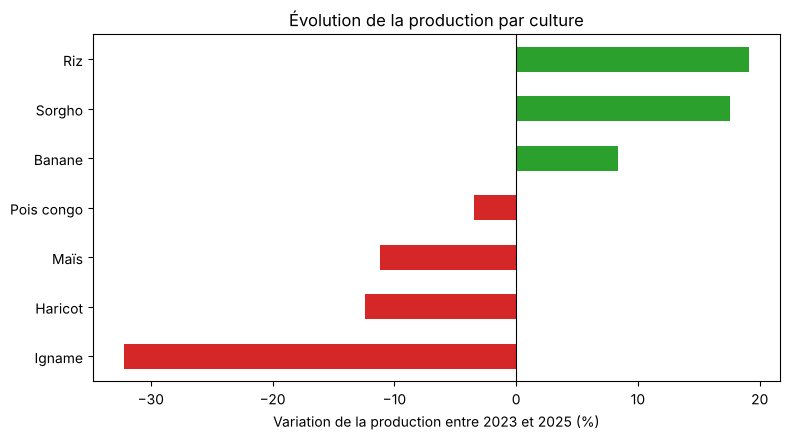

In [15]:
production = recoltes.pivot_table(index="culture", columns="annee", values="production_t", aggfunc="sum")
surfaces = recoltes.pivot_table(index="culture", columns="annee", values="surface_ha", aggfunc="sum")
rendement_annuel = production / surfaces

evolution = pd.DataFrame({
    "production 2023 (t)": production[2023],
    "production 2025 (t)": production[2025],
    "variation production (%)": ((production[2025] / production[2023] - 1) * 100).round(1),
    "variation surface (%)": ((surfaces[2025] / surfaces[2023] - 1) * 100).round(1),
    "variation rendement (%)": ((rendement_annuel[2025] / rendement_annuel[2023] - 1) * 100).round(1),
}).sort_values("variation production (%)", ascending=False)
print(evolution)
print()
print("Surfaces cultivées (ha) :")
print(surfaces)
print()
print("Rendement (t/ha) par année :")
print(rendement_annuel.round(2))

variation = evolution["variation production (%)"].sort_values()
fig, ax = plt.subplots(figsize=(8, 4.5))
variation.plot.barh(ax=ax, color=["tab:red" if v < 0 else "tab:green" for v in variation])
ax.axvline(0, color="black", linewidth=0.8)
ax.set_xlabel("Variation de la production entre 2023 et 2025 (%)")
ax.set_ylabel("")
ax.set_title("Évolution de la production par culture")
fig.tight_layout()
plt.show()

**Ce qu'on en conclut :** le riz (+19,1 %), le sorgho (+17,6 %) et la banane (+8,4 %) progressent entre 2023 et 2025 ; l'igname (-32,2 %), le haricot (-12,4 %), le maïs (-11,2 %) et le pois congo (-3,5 %) reculent. Pour l'igname et le sorgho, la variation vient surtout des surfaces : celle de l'igname baisse de 31,5 % (27 341 à 18 739 ha) alors que son rendement bouge à peine (5,92 à 5,86 t/ha). Pour le riz, elle vient surtout du rendement (2,63 à 3,00 t/ha).

## 8. Rapportez la production à la population de chaque département : quels départements produisent le plus par habitant ?

             tonnes  population  kg_par_habitant_an  gourdes_par_habitant_an
departement                                                                 
Grand'Anse   114384      468301                81.4                     1896
Centre       167080      746236                74.6                     1638
Sud          155168      774976                66.7                     1741
Nord-Est      75030      393967                63.5                     1536
Artibonite   269226     1727524                51.9                     1341
Nippes        49223      342525                47.9                     1136
Sud-Est       80796      632601                42.6                      905
Nord-Ouest    87192      728807                39.9                      941
Nord         118791     1067177                37.1                      953
Ouest        204866     4029705                16.9                      449


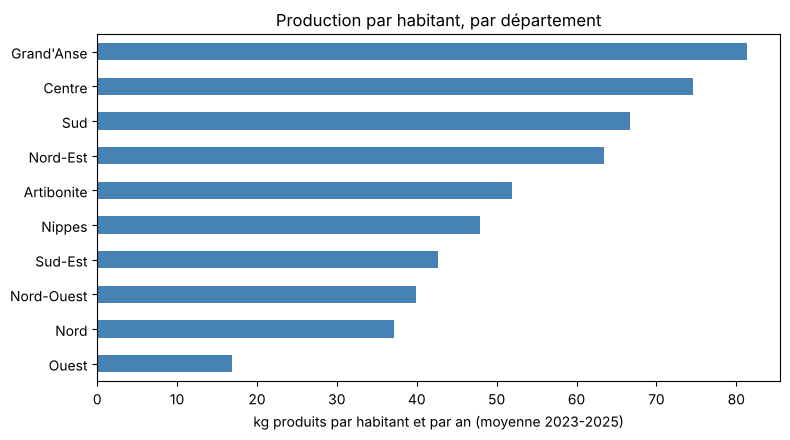

In [16]:
par_departement = recoltes.groupby("departement").agg(
    tonnes=("production_t", "sum"),
    valeur_htg=("valeur_htg", "sum"),
    population=("population", "first"),
)
nb_annees = recoltes["annee"].nunique()
par_departement["kg_par_habitant_an"] = (par_departement["tonnes"] * 1000 / par_departement["population"] / nb_annees).round(1)
par_departement["gourdes_par_habitant_an"] = (par_departement["valeur_htg"] / par_departement["population"] / nb_annees).round().astype(int)

classement = par_departement.sort_values("kg_par_habitant_an", ascending=False)
print(classement[["tonnes", "population", "kg_par_habitant_an", "gourdes_par_habitant_an"]])

fig, ax = plt.subplots(figsize=(8, 4.5))
classement["kg_par_habitant_an"].sort_values().plot.barh(ax=ax, color="steelblue")
ax.set_xlabel("kg produits par habitant et par an (moyenne 2023-2025)")
ax.set_ylabel("")
ax.set_title("Production par habitant, par département")
fig.tight_layout()
plt.show()

**Ce qu'on en conclut :** la Grand'Anse produit le plus par habitant (81,4 kg par an), devant le Centre (74,6 kg) et le Sud (66,7 kg). L'Ouest ferme la marche (16,9 kg) : c'est de loin le département le plus peuplé (4,03 millions d'habitants), alors qu'il est le deuxième producteur en tonnes (204 866 t).

## 9. Conclusion

Cinq phrases au plus : ce qu'il faut retenir, ce que les données ne permettent pas de dire, ce qu'il faudrait mesurer ensuite.

En tonnes, la banane et l'igname dominent, mais en valeur l'igname passe devant (12,07 milliards de gourdes contre 6,57) et le haricot et le pois congo gagnent deux places grâce à leur prix. Les meilleurs rendements dépendent de la culture (le Nord pour la banane, la Grand'Anse pour l'igname, l'Artibonite pour le riz), et par habitant la Grand'Anse (81,4 kg par an) devance le Centre (74,6 kg) alors que l'Ouest, très peuplé, est dernier (16,9 kg). La pluie va de pair avec le rendement pour toutes les cultures (corrélation de 0,42 pour le riz à 0,76 pour le haricot et le maïs), et entre 2023 et 2025 le riz (+19 %), le sorgho (+18 %) et la banane (+8 %) progressent tandis que l'igname recule de 32 %. Les données ne permettent pas de dire que la pluie est la cause des rendements (trois ans, 376 relevés, aucun autre facteur mesuré), ni de comparer partout le riz, cultivé dans cinq départements seulement. Il faudrait mesurer ensuite la pluie mois par mois, les prix réels d'une année à l'autre, et les engrais ou l'irrigation utilisés par département.